In [ ]:
import os

# For headless MuJoCo rendering on a remote GPU server
os.environ["MUJOCO_GL"] = "egl"

from dataclasses import dataclass, asdict
import numpy as np
import torch
import gymnasium as gym
import torch.nn as nn
from torch.distributions import Normal
import torch.nn.utils.parametrizations as param
from collections import deque
import torch.nn.functional as F
import matplotlib.pyplot as plt
import imageio.v2 as imageio
from pathlib import Path
from IPython.display import Video, display
import pandas as pd
from pathlib import Path
import json
import mujoco
import random

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import r2_score, silhouette_score
import matplotlib.cm as cm
import copy
from scipy.spatial.transform import Rotation as R



@dataclass
class LDRConfig:
    # SAC and training settings (Xu: configs/agents/hopper/ldr.yaml)
    total_timesteps: int = 1_500_000
    learning_starts: int = 0             # Xu: train_start_iterations = 0, policy acts from the start
    train_freq: int = 2048               # env steps collected per optimize() call
    gradient_steps: int = 2048           # gradient updates per optimize() call (1 per env step)
    batch_size: int = 256
    eval_interval: int = 100_000
    buffer_size: int = 1_000_000
    gamma: float = 0.99
    tau: float = 0.005
    learning_rate: float = 3e-4
    reward_scale: float = 0.008
    target_update_interval: int = 1
    hidden_dim: int = 256
    decoder_hidden_dim: int = 256
    seed: int = 1012

    # LDR-specific settings
    n_past: int = 50
    latent_dim: int = 3                  # Xu uses 5 only for Ant
    vae_loss_weight: float = 5.0
    contrastive_loss_weight: float = 1.0
    infonce_temp: float = 1.0
    contrastive_start_iterations: int = 100_000
    latent_dropout_prob: float = 0.1
    min_positives: int = 1

    # KL annealing (Xu's kl_schedule): beta goes 0 -> beta_max linearly
    # over the first beta_anneal_fraction of training, then stays at beta_max
    beta_max: float = 0.1
    beta_anneal_fraction: float = 0.5
    encoder_reg_mode: str = "none" #specify "none", "l2", or "spectral" or "orthogonal" for encoder regularization



    #FDCL
    use_fdcl: bool = True            # False -> fall back to Xu's multi-positive InfoNCE
    fdcl_num_refs: int = 32          # K common reference (s, a) pairs
    fdcl_eta: float = 1.0            # η: target sharpness on d_ij
    fdcl_temp: float = 1.0           # τ: student temperature
    ema_rho: float = 0.99            # ρ: teacher EMA momentum


ENV_PRESETS = {
    "Hopper-v5":      dict(latent_dim=3, reward_scale=0.008, beta_max=0.10, learning_rate=3e-4, decoder_hidden_dim=256),
    "Walker2d-v5":    dict(latent_dim=3, reward_scale=0.004, beta_max=0.07, learning_rate=3e-4, decoder_hidden_dim=256),
    "HalfCheetah-v5": dict(latent_dim=3, reward_scale=0.004, beta_max=0.07, learning_rate=3e-4, decoder_hidden_dim=256),
    "Ant-v5":         dict(latent_dim=5, reward_scale=0.006, beta_max=0.04, learning_rate=1e-4, decoder_hidden_dim=512),
}

In [2]:
def applyLipschitzRegularization(module, reg_mode):
    """Recursively apply spectral/orthogonal parametrization to Linear and Conv1d children (Xu)."""
    if reg_mode not in ("spectral", "orthogonal", "none"):
        raise ValueError(f"Invalid reg_mode '{reg_mode}'")
    if reg_mode == "none":
        return module
    for child in module.children():
        if isinstance(child, (nn.Linear, nn.Conv1d)):
            if reg_mode == "spectral":
                param.spectral_norm(child, name="weight")
            else:
                param.orthogonal(child, name="weight")
        else:
            applyLipschitzRegularization(child, reg_mode)
    return module

In [3]:
class HistoryQueue:
    def __init__(self, n_envs, n_past, obs_dim, action_dim):
        self.n_envs, self.H, self.obs_dim, self.action_dim = n_envs, n_past, obs_dim, action_dim
        self.data = np.zeros((n_envs, n_past, obs_dim + action_dim), dtype=np.float32)
    
    def get(self):
        return self.data.copy()
    
    def append(self, obs, actions):
        # shifting all data except the last 1 row. then add the new obs and actions to the first row
        self.data[:,1:] = self.data[:,:-1].copy()
        self.data[:,0,:self.obs_dim] = obs
        self.data[:,0,self.obs_dim:] = actions
    
    # def reset_done(self, dones):
    #     self.data[np.asarray(dones, dtype=bool)] = 0

    def reset_done(self, dones, initial_obs):
        dones = np.asarray(dones, dtype=bool)
        self.data[dones] = 0
        if initial_obs is not None:
            self.data[dones, :, :self.obs_dim] = initial_obs[dones][:, None, :]


In [4]:
# Need to send latent_dim from the LDRAgent

class Actor(nn.Module):

    def __init__(self, obs_dim, action_dim, hidden_dim=256, latent_dim=0):
        super().__init__()
        self.latent_dim = latent_dim
        if latent_dim > 0:
            self.latent_norm = nn.LayerNorm(latent_dim)

        # Shared feature extractor
        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU()
        )

        # Gaussian distribution parameters
        self.mu = nn.Linear(hidden_dim, action_dim)
        self.log_std = nn.Linear(hidden_dim, action_dim)
        self.log_std_min = -20
        self.log_std_max = 2

    def forward(self, obs):
        # obs = [env_obs, z]; normalize z before the MLP
        if self.latent_dim > 0:
            s, z = obs[..., :-self.latent_dim], obs[..., -self.latent_dim:]
            obs = torch.cat([s, self.latent_norm(z)], dim=-1)

        features = self.net(obs)
        mean = self.mu(features)
        log_std = self.log_std(features)
        log_std = torch.clamp(log_std, self.log_std_min, self.log_std_max)  
        std = log_std.exp()

        return mean, std


    # Sample actions and compute log probabilities
    def actionLogProb(self, obs):

        mean, std = self.forward(obs)
        dist = Normal(mean, std)
        u = dist.rsample() # reparameterization trick for backpropagation
        action = torch.tanh(u) # action between -1 and 1

        # Calculting log \pi(a|S)
        log_prob = dist.log_prob(u)
        log_prob -= 2 * (torch.log(torch.tensor(2.0, device=u.device)) - u - nn.functional.softplus(-2 * u))
        log_prob = log_prob.sum(dim=-1, keepdim=True)

        return action, log_prob

    def predict(self, obs, deterministic=True):
        """Return normalized actions for inference."""

        mean, std = self.forward(obs)

        if deterministic:
            return torch.tanh(mean)

        dist = Normal(mean, std)
        return torch.tanh(dist.sample())


In [5]:
class Critic(nn.Module):

    def __init__(self, obs_dim, action_dim, hidden_dim=256, latent_dim=0):
        super().__init__()

        input_dim = obs_dim + action_dim
        self.latent_dim = latent_dim

        # First Q network
        self.q1 = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

        # Second Q network
        self.q2 = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

        # One LayerNorm per Q head (Xu deep-copies the extractor for each head)
        if latent_dim > 0:
            self.norm1 = nn.LayerNorm(latent_dim)
            self.norm2 = nn.LayerNorm(latent_dim)

    def _input(self, obs, action, norm):
        if self.latent_dim > 0:
            s, z = obs[..., :-self.latent_dim], obs[..., -self.latent_dim:]
            obs = torch.cat([s, norm(z)], dim=-1)
        return torch.cat([obs, action], dim=-1)

    def forward(self, obs, action):
        if self.latent_dim > 0:
            q1 = self.q1(self._input(obs, action, self.norm1))
            q2 = self.q2(self._input(obs, action, self.norm2))
        else:
            x = torch.cat([obs, action], dim=-1)
            q1, q2 = self.q1(x), self.q2(x)

        return q1, q2



In [6]:
class ReplayBuffer:

    def __init__(self, buffer_size, num_envs, obs_dim, action_dim, device, n_past):

        self.num_envs = num_envs
        self.obs_dim = obs_dim
        self.action_dim = action_dim
        self.device = torch.device(device)

        # Capacity measured in vectorized steps
        self.capacity = max(buffer_size // num_envs, 1 )

        # Allocate storage
        self.obs = np.zeros((self.capacity, num_envs, obs_dim), dtype=np.float32)
        self.next_obs = np.zeros_like(self.obs)
        self.actions = np.zeros((self.capacity, num_envs, action_dim), dtype=np.float32)
        self.rewards = np.zeros((self.capacity, num_envs), dtype=np.float32)
        self.dones = np.zeros((self.capacity, num_envs), dtype=np.float32)
        self.timeouts = np.zeros_like(self.dones)

        # LDR specific
        self.histories = np.zeros((self.capacity, num_envs, n_past, obs_dim + action_dim), dtype=np.float32)
        self.dynamics_ids = np.zeros((self.capacity, num_envs), dtype=np.int64)

        self.pos = 0
        self.full = False

    def push(self, obs, next_obs, actions, rewards, dones, timeouts, history, dynamics_ids):

        self.obs[self.pos] = obs
        self.next_obs[self.pos] = next_obs
        self.actions[self.pos] = actions
        self.rewards[self.pos] = rewards
        self.dones[self.pos] = dones
        self.timeouts[self.pos] = timeouts
        self.histories[self.pos] = history
        self.dynamics_ids[self.pos] = dynamics_ids

        # Circular buffer
        self.pos += 1
        if self.pos >= self.capacity:
            self.pos = 0
            self.full = True

    # bookkeeping, length of stored transition
    def __len__(self):
        steps = self.capacity if self.full else self.pos
        return steps * self.num_envs

    def sample(self, batch_size):

        size = self.capacity if self.full else self.pos

        if size == 0:
            raise ValueError("Cannot sample an empty buffer")

        # Random time & environment indices
        batch_indices = np.random.randint(0, size, size=batch_size)
        env_indices = np.random.randint(0, self.num_envs, size=batch_size)

        obs = self.obs[batch_indices, env_indices]
        next_obs = self.next_obs[batch_indices, env_indices]
        actions = self.actions[batch_indices, env_indices]
        rewards = self.rewards[batch_indices, env_indices].reshape(-1, 1) #reshapes into a column vector for each transition
        dones = self.dones[batch_indices, env_indices].reshape(-1, 1)
        timeouts = self.timeouts[batch_indices, env_indices].reshape(-1, 1)
        history= self.histories[batch_indices, env_indices]
        ids = self.dynamics_ids[batch_indices, env_indices]

        # Only true terminations stop bootstrapping
        dones = dones * (1.0 - timeouts)

        def to_tensor(x):
            return torch.as_tensor(x, dtype=torch.float32, device=self.device)

        return {
            "obs": to_tensor(obs),
            "next_obs": to_tensor(next_obs),
            "actions": to_tensor(actions),
            "rewards": to_tensor(rewards),
            "dones": to_tensor(dones),
            "history": to_tensor(history),
            "ids": torch.as_tensor(ids, dtype=torch.long, device=self.device)
        }


In [7]:
class DynamicsEncoder(nn.Module):

    def __init__(
            self, 
            obs_dim, 
            action_dim, 
            H, 
            latent_dim, 
            embed_dim=32, 
            kernel_sizes=(8, 5, 5), 
            strides=(4, 1, 1), 
            log_std_min=-20.0, 
            log_std_max=2.0,
            reg_mode="none"
            ):
        super().__init__()
        input_dim = obs_dim + action_dim

        # Per-timestep (obs, action) embedding, shared across time; no ReLU on the output
        self.embedding = nn.Sequential(
            nn.Linear(input_dim, embed_dim),
            nn.ReLU(),
            nn.Linear(embed_dim, embed_dim),
        )

        # TCN: Conv1d + ReLU blocks over the time axis
        tcn_layers = []
        for k, s in zip(kernel_sizes, strides):
            tcn_layers += [nn.Conv1d(embed_dim, embed_dim, kernel_size=k, stride=s), nn.ReLU()]
        self.tcn = nn.Sequential(*tcn_layers)

        # Flattened TCN output size (96 for H=50 with the default kernels/strides)
        with torch.no_grad():
            dummy = torch.zeros(1, H, input_dim)
            flat_size = self.tcn(self.embedding(dummy).permute(0, 2, 1)).reshape(1, -1).size(1)

        self.mean = nn.Linear(flat_size, latent_dim)
        self.log_std = nn.Linear(flat_size, latent_dim)
        self.log_std_min = log_std_min
        self.log_std_max = log_std_max

        # lipchitz regularization
        self.embedding = applyLipschitzRegularization(self.embedding, reg_mode)
        self.tcn = applyLipschitzRegularization(self.tcn, reg_mode)

    def forward(self, history):
        # history: (B, H, obs+act), newest first -> flip to oldest first
        x = torch.flip(history, dims=[1])
        x = self.embedding(x).permute(0, 2, 1)       # (B, embed_dim, H)
        x = self.tcn(x).reshape(x.size(0), -1)       # (B, flat_size)

        log_std = self.log_std(x).clamp(self.log_std_min, self.log_std_max)
        return Normal(self.mean(x), log_std.exp())

In [8]:
class RunningMeanStd(nn.Module):
    """Running mean/var of the target delta (buffers, not trained)."""

    def __init__(self, shape, epsilon=1e-5, clip_limit=10.0):
        super().__init__()
        self.register_buffer("mean", torch.zeros(shape))
        self.register_buffer("var", torch.ones(shape))
        self.register_buffer("count", torch.tensor(1e-4))
        self.epsilon = epsilon
        self.clip_limit = clip_limit

    @torch.no_grad()
    def update(self, x):
        batch_mean = x.mean(dim=0)
        batch_var = x.var(dim=0, unbiased=False)
        batch_count = x.shape[0]

        delta = batch_mean - self.mean
        tot_count = self.count + batch_count
        new_mean = self.mean + delta * batch_count / tot_count
        M2 = self.var * self.count + batch_var * batch_count + delta**2 * self.count * batch_count / tot_count

        self.mean.copy_(new_mean)
        self.var.copy_(M2 / tot_count)
        self.count.copy_(tot_count)

    def normalize(self, x):
        return torch.clamp((x - self.mean) / torch.sqrt(self.var + self.epsilon), -self.clip_limit, self.clip_limit)

    def denormalize(self, x):
        return x * torch.sqrt(self.var + self.epsilon) + self.mean


class DynamicsDecoder(nn.Module):

    def __init__(self, obs_dim, action_dim, latent_dim, hidden=256):
        super().__init__()
        self.latent_dim = latent_dim

        # LayerNorm on z before the MLP (Xu's LatentMLPFeatureExtractor backbone)
        self.latent_norm = nn.LayerNorm(latent_dim)

        self.net = nn.Sequential(
            nn.Linear(obs_dim + action_dim + latent_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU()
        )

        # Predicts the NORMALIZED change in observation
        self.mean = nn.Linear(hidden, obs_dim)
        self.log_std = nn.Linear(hidden, obs_dim)

        self.target_scaler = RunningMeanStd(shape=(obs_dim,))

    def forward(self, obs, action, z):
        x = self.net(torch.cat((obs, action, self.latent_norm(z)), dim=-1))
        return Normal(self.mean(x), self.log_std(x).clamp(-20, 2).exp())

    def logProb(self, obs, next_obs, action, z):
        """Log prob of the observed transition, with target normalization (as in Xu)."""
        delta_obs = next_obs - obs
        if self.training:
            self.target_scaler.update(delta_obs.detach())
        return self(obs, action, z).log_prob(self.target_scaler.normalize(delta_obs))

    @torch.no_grad()
    def predictNextObs(self, obs, action, z):
        """Denormalized next-obs prediction (for visualization)."""
        delta = self.target_scaler.denormalize(self(obs, action, z).mean)
        return obs + delta

In [9]:
def multi_positive_infonce(z, ids, temperature):
    z = F.normalize(z, dim=-1) #projecting onto unit sphere

    logits = z @ z.T / temperature  # Matrix of pairwise similarities

    self_mask = torch.eye(z.shape[0], dtype=torch.bool, device=z.device) # Self similarities, diagonal of the logits matrix
    positive = (ids[:, None] == ids[None, :]) & ~self_mask
    counts = positive.sum(dim=1)
    valid = counts > 0

    log_den = torch.logsumexp(logits.masked_fill(self_mask, float('-inf')), dim=1)
    log_prob = logits - log_den[:, None]
    per_anchor = -(log_prob.masked_fill(~positive, 0).sum(dim=1) / counts.clamp_min(1))
    
    # Xu averages over ALL anchors; anchors without positives contribute 0
    return per_anchor.mean(), float(valid.float().mean().item())

In [10]:
def fdcl_loss(z, d, eta, tau):
    """z: student means (B, d_z); d: functional distances (B, B), no grad."""
    B = z.shape[0]
    self_mask = torch.eye(B, dtype=torch.bool, device=z.device)

    # q_ij = softmax_{j != i}(-d_ij / η)
    with torch.no_grad():
        q = torch.softmax((-d / eta).masked_fill(self_mask, float('-inf')), dim=1)

    # p_ij = softmax_{j != i}(sim(z_i, z_j) / τ), cosine similarity as in Xu
    zn = F.normalize(z, dim=-1)
    logits = (zn @ zn.T / tau).masked_fill(self_mask, float('-inf'))
    log_p = torch.log_softmax(logits, dim=1).masked_fill(self_mask, 0.0)  # avoid 0 * -inf = nan

    return -(q * log_p).sum(dim=1).mean()

In [ ]:
class LDRAgent:

    def __init__(self, env, env_ID, config=None, device=None):

        self.env = env
        self.env_ID = env_ID
        self.env_name = self.env_ID.split("-")[0].lower()
        self.config = config or LDRConfig()
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu" ))
        self.num_envs = env.num_envs
        self.obs_dim = env.observation_space.shape[0]
        self.action_dim = env.action_space.shape[0]
        self.action_low = np.asarray(env.action_space.low, dtype=np.float32)
        self.action_high = np.asarray(env.action_space.high, dtype=np.float32)
        
        # # Safety checks for action space
        # assert isinstance(env.action_space, gym.spaces.Box)
        # assert np.all(np.isfinite(self.action_low))
        # assert np.all(np.isfinite(self.action_high))
        # assert np.all(self.action_high > self.action_low)

        # Training counters
        self.num_timesteps = 0
        self.num_updates = 0

        # Track running returns for each parallel environment.
        self.episode_returns = np.zeros(self.num_envs, dtype=np.float64)
        self.completed_returns = []

        self.last_obs = None #current observations
        self.target_entropy = -float(self.action_dim) # SAC entropy target





        # Actor and Critic Networks 
        input_dim = self.obs_dim + self.config.latent_dim

        self.actor = Actor(
            obs_dim=input_dim, 
            action_dim=self.action_dim,
            hidden_dim=self.config.hidden_dim, 
            latent_dim=self.config.latent_dim
            ).to(self.device)

        self.actor_optimizer = torch.optim.Adam(self.actor.parameters(), lr=self.config.learning_rate) 

        self.critic = Critic(
            obs_dim=input_dim, 
            action_dim=self.action_dim,
            hidden_dim=self.config.hidden_dim, 
            latent_dim=self.config.latent_dim
            ).to(self.device)

        self.critic_target = Critic(
            obs_dim=input_dim, 
            action_dim=self.action_dim, 
            hidden_dim=self.config.hidden_dim, 
            latent_dim=self.config.latent_dim
            ).to(self.device)

        # Initially copying online weights to target
        self.critic_target.load_state_dict(self.critic.state_dict())

        # Target network is not trained by gradient descent rather updated from online Critic using Polyak averaging
        for param in self.critic_target.parameters():
            param.requires_grad_(False)

        self.critic_optimizer = torch.optim.Adam(self.critic.parameters(), lr=self.config.learning_rate)






        # Encoder & Decoder
        self.encoder = DynamicsEncoder(
            self.obs_dim, 
            self.action_dim, 
            self.config.n_past, 
            self.config.latent_dim,
            reg_mode = self.config.encoder_reg_mode,
            ).to(self.device)
        self.encoder_optimizer = torch.optim.Adam(self.encoder.parameters(), lr=self.config.learning_rate)

        self.decoder = DynamicsDecoder(
            self.obs_dim, 
            self.action_dim, 
            self.config.latent_dim, 
            self.config.decoder_hidden_dim
            ).to(self.device)
        self.decoder_optimizer = torch.optim.Adam(self.decoder.parameters(), lr=self.config.learning_rate)


        # FDCL specific
        self.teacher_encoder = copy.deepcopy(self.encoder)
        self.teacher_decoder = copy.deepcopy(self.decoder)
        for m in (self.teacher_encoder, self.teacher_decoder):
            m.eval()
            for p in m.parameters():
                p.requires_grad_(False)


        self.history_queue = HistoryQueue(self.num_envs, self.config.n_past, self.obs_dim, self.action_dim)
        
        self.replay_buffer = ReplayBuffer(
            buffer_size = self.config.buffer_size, 
            num_envs = self.num_envs, 
            obs_dim = self.obs_dim, 
            action_dim = self.action_dim, 
            device = self.device, 
            n_past = self.config.n_past
            )

        # Learnable log entropy coefficient
        self.log_alpha = torch.zeros(1, device=self.device, requires_grad=True)
        self.alpha_optimizer = torch.optim.Adam([self.log_alpha], lr=self.config.learning_rate)


    # polyak averaging for target network update
    def update_target(self):
        tau = self.config.tau
        with torch.no_grad():
            for param, target_param in zip(self.critic.parameters(), self.critic_target.parameters()):
                target_param.mul_(1 - tau)
                target_param.add_(tau * param)


    @torch.no_grad()
    def update_teacher(self):
        rho = self.config.ema_rho
        for s_mod, t_mod in ((self.encoder, self.teacher_encoder),
                             (self.decoder, self.teacher_decoder)):
            for p, tp in zip(s_mod.parameters(), t_mod.parameters()):
                tp.mul_(rho).add_(p, alpha=1.0 - rho)
            # copy (not average) the decoder's running target-normalization stats
            for b, tb in zip(s_mod.buffers(), t_mod.buffers()):
                tb.copy_(b)

    @torch.no_grad()
    def functional_distance(self, history, ref_obs, ref_act):
        """d_ij = (1/K) Σ_k ||D̄(s_k, a_k, z̃_i) - D̄(s_k, a_k, z̃_j)||²"""
        z_t = self.teacher_encoder(history).loc                  # z̃_i = μ_φ̄(h_i), (B, d_z)
        B, K = z_t.shape[0], ref_obs.shape[0]
        s = ref_obs.unsqueeze(0).expand(B, K, -1)
        a = ref_act.unsqueeze(0).expand(B, K, -1)
        z = z_t.unsqueeze(1).expand(B, K, -1)
        f = self.teacher_decoder(s, a, z).mean.reshape(B, -1)    # (B, K*obs_dim)
        return torch.cdist(f, f).pow(2) / K


    # Convert normalized actions [-1, 1] to environment bounds
    def _toEnvAction(self, action):
        return (self.action_low + 0.5 * (self.action_high - self.action_low) * (action + 1.0))

    # Convert environment actions back to [-1, 1].
    def _reverseEnvAction(self, action):
        return (2.0 * (action - self.action_low) / (self.action_high - self.action_low) - 1.0)

    
    
    def predict(self, obs, history=None, deterministic=True, train_dropout=False):

        obs = torch.as_tensor(obs, dtype=torch.float32, device=self.device )

        if obs.ndim == 1:
            obs = obs.unsqueeze(0)

        if history is None:
            history = self.history_queue.get()

        self.actor.eval()
        self.encoder.eval()

        with torch.no_grad():
            z = self._latent(history, train_dropout=train_dropout)
            x = torch.cat([obs, z], dim=-1)
            action = self.actor.predict(x, deterministic=deterministic)

        return self._toEnvAction(action.cpu().numpy())


    def _latent(self, history, train_dropout=False):

        history = torch.as_tensor(history, dtype=torch.float32, device=self.device )

        if history.ndim == 2:
            history = history.unsqueeze(0)

        with torch.no_grad():
            z = self.encoder(history).loc

            if train_dropout and self.config.latent_dropout_prob > 0:
                keep = (
                    torch.rand((z.shape[0], 1), device=self.device)
                    >= self.config.latent_dropout_prob
                ).float()
                z = z * keep

        return z


    def _selectAction(self, obs, deterministic=False):

        if self.num_timesteps < self.config.learning_starts:

            # Random normalized actions during warm-up
            action = np.random.uniform(-1.0, 1.0, size=(self.num_envs, self.action_dim) ).astype(np.float32)

        else:
            # Predict environment-scaled actions
            env_action = self.predict(obs, deterministic=deterministic, train_dropout=not deterministic)

            # Convert back to normalized [-1, 1]
            action = self._reverseEnvAction(env_action)

        return np.clip(action, -1.0, 1.0).astype(np.float32)



    # Collect transitions using vectorized environments
    def explore(self):

        if self.last_obs is None:
            self.last_obs = self.env.reset()

        collected_steps = 0

        while collected_steps < self.config.train_freq:

            history=self.history_queue.get()  # history BEFORE current action
            ids= self.env.dynamics_ids.copy()  # capture pre-step dynamics IDs (auto-reset may change them)

            buffer_actions = self._selectAction(self.last_obs, deterministic=False)
            env_actions = self._toEnvAction(buffer_actions) #scaling to environment action space before applying

            new_obs, rewards, dones, infos = self.env.step(env_actions)

            self.episode_returns += np.asarray(rewards, dtype=np.float64)
            
            for i in np.flatnonzero(dones):
                self.completed_returns.append(float(self.episode_returns[i]))
                self.episode_returns[i] = 0.0

            # 4. Identify time-limit truncations
            timeouts = np.array(
                [
                    info.get("TimeLimit.truncated", False)
                    for info in infos
                ],
                dtype=np.float32
            )

            # 5. Preserve actual terminal observations
            buffer_next_obs = new_obs.copy()

            for i in range(self.num_envs):
                if dones[i]:
                    buffer_next_obs[i] = infos[i]["terminal_observation"]

            
            self.replay_buffer.push(
                obs=self.last_obs,
                next_obs=buffer_next_obs,
                actions=buffer_actions,
                rewards=rewards,
                dones=dones,
                timeouts=timeouts,
                history = history,
                dynamics_ids=ids
            )

            self.history_queue.append(self.last_obs, buffer_actions)
            self.history_queue.reset_done(dones, new_obs)
            self.last_obs = new_obs.copy()
            self.num_timesteps += self.num_envs
            collected_steps += self.num_envs

        return collected_steps

    
    def optimize(self):

        self.actor.train()
        self.critic.train()
        self.encoder.train()
        self.decoder.train()

        metrics = {
            "actor_loss": [],
            "critic_loss": [],
            "alpha_loss": [],
            "alpha": [],
            "vae_loss": [],
            "contrastive_loss": [],
            "positive_fraction": [],
            "fdcl_dist_median": []
        }

        for _ in range(self.config.gradient_steps):

            batch = self.replay_buffer.sample(self.config.batch_size)

            obs = batch["obs"]
            actions = batch["actions"]
            rewards = batch["rewards"]
            next_obs = batch["next_obs"]
            dones = batch["dones"]

            # LDR-specific
            history = batch["history"]
            dynamics_ids = batch["ids"]

            
            qz = self.encoder(history)
            z = qz.rsample()

            # Latent dropout
            keep = (torch.rand((z.shape[0], 1), device=self.device)  >=   self.config.latent_dropout_prob).float()
            z_rl = z * keep # sampled latent including dropout for RL training

            # Condition observations on latent dynamics
            obs_z = torch.cat([obs, z_rl], dim=-1)
            next_obs_z = torch.cat([next_obs, z_rl.detach()], dim=-1)

            # entropy coefficient
            alpha = self.log_alpha.exp().detach()

            # training critic with target Q-values
            with torch.no_grad():

                next_actions, next_log_prob = (self.actor.actionLogProb(next_obs_z) )
                next_q1, next_q2 = self.critic_target(next_obs_z, next_actions)
                next_q = (torch.min(next_q1, next_q2) - alpha * next_log_prob)

                target_q = (rewards * self.config.reward_scale + self.config.gamma * (1.0 - dones) * next_q )

            
            q1, q2 = self.critic(obs_z.detach(), actions)
            critic_loss = 0.5 * (F.mse_loss(q1, target_q) + F.mse_loss(q2, target_q) )

            self.critic_optimizer.zero_grad()
            critic_loss.backward()
            self.critic_optimizer.step()

            # training actor with policy gradient
            new_actions, log_prob = (self.actor.actionLogProb(obs_z)  )

            # Freeze critic temporarily
            # for param in self.critic.parameters():
            #     param.requires_grad_(False)

            # (no critic freeze, as in Xu: gradients the actor loss leaves on the critic
            #  are cleared by critic_optimizer.zero_grad() before the next critic update)
            q1_pi, q2_pi = self.critic(obs_z, new_actions)
            min_q_pi = torch.min(q1_pi, q2_pi)

            actor_loss = (alpha * log_prob - min_q_pi).mean()



            # VAE reconstruction loss
            recon_loss = -self.decoder.logProb(obs, next_obs, actions, z).mean()

            # KL divergence 
            kl_loss = 0.5 * (qz.loc.square() + qz.scale.square() - 1.0 - 2.0 * qz.scale.log()).sum(dim=-1).mean()
            
            progress = min(self.num_timesteps / self.config.total_timesteps, 1.0)
            beta = self.config.beta_max * min(progress / self.config.beta_anneal_fraction, 1.0)
            vae_loss = recon_loss + beta * kl_loss


            # Contrastive loss (InfoNCE) for latent dynamics
            # contrastive_loss = z.sum() * 0.0
            # positive_fraction = 0.0

            # if (self.num_timesteps >= self.config.contrastive_start_iterations):
            #     contrastive_loss, positive_fraction = (
            #         multi_positive_infonce(z, dynamics_ids, self.config.infonce_temp)
            #     )


            # FDCL loss
            contrastive_loss = z.sum() * 0.0
            positive_fraction = 0.0
            fdcl_dist_median = 0.0

            if self.num_timesteps >= self.config.contrastive_start_iterations:
                if self.config.use_fdcl:
                    # K common reference (s, a) pairs drawn from this replay-buffer batch
                    ref_idx = torch.randperm(obs.shape[0], device=self.device)[:self.config.fdcl_num_refs]
                    d = self.functional_distance(history, obs[ref_idx], actions[ref_idx])
                    contrastive_loss = fdcl_loss(qz.loc, d, self.config.fdcl_eta, self.config.fdcl_temp)
                    off = ~torch.eye(d.shape[0], dtype=torch.bool, device=d.device)
                    fdcl_dist_median = d[off].median().item()
                else:
                    contrastive_loss, positive_fraction = multi_positive_infonce(
                        z, dynamics_ids, self.config.infonce_temp)



            # Combined total loss for actor, encoder, and decoder
            total_loss = (actor_loss + self.config.vae_loss_weight * vae_loss + self.config.contrastive_loss_weight * contrastive_loss)

            self.actor_optimizer.zero_grad()
            self.encoder_optimizer.zero_grad()
            self.decoder_optimizer.zero_grad()

            total_loss.backward()

            self.actor_optimizer.step()
            self.encoder_optimizer.step()
            self.decoder_optimizer.step()

            # FDCL
            self.update_teacher()          # ← new

            # Restore critic gradients
            # for param in self.critic.parameters():
            #     param.requires_grad_(True)

            # Update entropy coefficient
            alpha_loss = -(self.log_alpha * (log_prob.detach() + self.target_entropy)).mean()
            self.alpha_optimizer.zero_grad()
            alpha_loss.backward()
            self.alpha_optimizer.step()

            # update target networks using Polyak averaging
            self.num_updates += 1

            if (self.num_updates % self.config.target_update_interval == 0):
                self.update_target()

            # Saving metrics for logging
            metrics["actor_loss"].append(actor_loss.item())
            metrics["critic_loss"].append(critic_loss.item())
            metrics["alpha_loss"].append(alpha_loss.item())
            metrics["alpha"].append(alpha.item())
            metrics["vae_loss"].append(vae_loss.item())
            metrics["contrastive_loss"].append(contrastive_loss.item())
            metrics["fdcl_dist_median"].append(fdcl_dist_median)

            if torch.is_tensor(positive_fraction):
                positive_fraction = positive_fraction.item()

            metrics["positive_fraction"].append(float(positive_fraction) )

        return {key: float(np.mean(values)) for key, values in metrics.items()}


    # Evaluates Deterministic LDR policy
    def evaluate(self, eval_env, eval_num=1, seed=None):


        self.actor.eval()
        self.encoder.eval()

        num_envs = eval_env.num_envs
        all_returns = []

        for episode in range(eval_num):

            if seed is not None:
                eval_env.seed(seed + episode * num_envs)

            obs = eval_env.reset()

            
            history = HistoryQueue(
                num_envs,
                self.config.n_past,
                self.obs_dim,
                self.action_dim
            )
            history.reset_done(np.ones(num_envs, dtype=bool), obs)

            episode_returns = np.zeros(num_envs, dtype=np.float64)

            # Track which environments have finished
            finished = np.zeros(num_envs, dtype=bool)

            while not np.all(finished):

                # LDR: predict using current obs and past history
                actions = self.predict(
                    obs,
                    history=history.get(),
                    deterministic=True
                )

                next_obs, rewards, dones, infos = eval_env.step(actions)

                episode_returns[~finished] += rewards[~finished]

                # LDR specific: store normalized actions in history
                normalized_actions = self._reverseEnvAction(actions)

                history.append(obs, normalized_actions)
                history.reset_done(dones, next_obs) 

                obs = next_obs
                finished |= dones

            all_returns.extend(episode_returns.tolist())

        return float(np.mean(all_returns))



    def train(self, eval_env=None, eval_num=1, RUN_DIR=Path("hopper_ldr_results")):

        RUN_DIR = Path(RUN_DIR)
        RUN_DIR.mkdir(parents=True, exist_ok=True)

        self.env.seed(self.config.seed)
        self.last_obs = self.env.reset()

        # LDR-specific: Reset history queue
        # self.history_queue.reset_done(np.ones(self.num_envs, dtype=bool))
        self.history_queue.reset_done(np.ones(self.num_envs, dtype=bool), self.last_obs)

        # Reset counters and reward tracking
        self.num_timesteps = 0
        self.num_updates = 0

        self.episode_returns.fill(0.0)
        self.completed_returns.clear()

        # Evaluation tracking
        best_eval_reward = float("-inf")

        next_eval_step = self.config.eval_interval

        training_history = []

        while self.num_timesteps < self.config.total_timesteps:

            collected_steps = self.explore()

            metrics = None

            if (self.num_timesteps >= self.config.learning_starts) and (len(self.replay_buffer) >= self.config.batch_size):
                metrics = self.optimize()

            if metrics is not None:
                metrics["timesteps"] = self.num_timesteps
                training_history.append(metrics)

            if (eval_env is not None) and (self.num_timesteps >= next_eval_step):

                eval_reward = self.evaluate(eval_env, eval_num=eval_num, seed=0)
                print(f"Steps: {self.num_timesteps} | Eval reward: {eval_reward:.2f}")

                if eval_reward > best_eval_reward:
                    best_eval_reward = eval_reward
                    self.save(RUN_DIR / f"{self.env_name}_ldr_fn_best.pt")
                    print(f"New best reward: {best_eval_reward:.2f}")

                # Advance evaluation threshold
                while next_eval_step <= self.num_timesteps:
                    next_eval_step += self.config.eval_interval

        print("Training completed!")

        return training_history


    
    
    def save(self, path):

        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)

        torch.save({
            "actor": self.actor.state_dict(),
            "critic": self.critic.state_dict(),
            "critic_target": self.critic_target.state_dict(),

            # LDR networks
            "encoder": self.encoder.state_dict(),
            "decoder": self.decoder.state_dict(),

            # SAC optimizers
            "actor_optimizer": self.actor_optimizer.state_dict(),
            "critic_optimizer": self.critic_optimizer.state_dict(),

            # LDR optimizers
            "encoder_optimizer": self.encoder_optimizer.state_dict(),
            "decoder_optimizer": self.decoder_optimizer.state_dict(),

            # FDCL 
            "teacher_encoder": self.teacher_encoder.state_dict(),
            "teacher_decoder": self.teacher_decoder.state_dict(),

            # Entropy coefficient
            "log_alpha": self.log_alpha.detach().cpu(),
            "alpha_optimizer": self.alpha_optimizer.state_dict(),

            # Training progress
            "num_timesteps": self.num_timesteps,
            "num_updates": self.num_updates,

            # Configuration
            "config": asdict(self.config)

        }, path)


    def load(self, path):

        checkpoint = torch.load(
            path,
            map_location=self.device,
            weights_only=True
        )

        # SAC networks
        self.actor.load_state_dict(checkpoint["actor"])
        self.critic.load_state_dict(checkpoint["critic"])
        self.critic_target.load_state_dict(
            checkpoint["critic_target"]
        )

        # LDR networks
        self.encoder.load_state_dict(checkpoint["encoder"])
        self.decoder.load_state_dict(checkpoint["decoder"])

        # FDCL networks
        self.teacher_encoder.load_state_dict(checkpoint.get("teacher_encoder", self.encoder.state_dict()))
        self.teacher_decoder.load_state_dict(checkpoint.get("teacher_decoder", self.decoder.state_dict()))

        
        # SAC optimizers
        self.actor_optimizer.load_state_dict(
            checkpoint["actor_optimizer"]
        )
        self.critic_optimizer.load_state_dict(
            checkpoint["critic_optimizer"]
        )

        # LDR optimizers
        self.encoder_optimizer.load_state_dict(
            checkpoint["encoder_optimizer"]
        )
        self.decoder_optimizer.load_state_dict(
            checkpoint["decoder_optimizer"]
        )

        # Entropy coefficient
        with torch.no_grad():
            self.log_alpha.copy_(
                checkpoint["log_alpha"].to(self.device)
            )

        self.alpha_optimizer.load_state_dict(
            checkpoint["alpha_optimizer"]
        )

        # Training progress
        self.num_timesteps = checkpoint["num_timesteps"]
        self.num_updates = checkpoint["num_updates"]

        # Target critic is not trained directly
        self.critic_target.eval()



In [13]:
class makeVecEnv:
    def __init__(self, env_fns):
        self.envs = [fn() for fn in env_fns]
        self.num_envs = len(self.envs)
        self.dynamics_ids = np.zeros(self.num_envs, dtype=np.int64)
        self.observation_space = self.envs[0].observation_space
        self.action_space = self.envs[0].action_space

    def seed(self, seed):
        self._seed = seed

    def reset(self):
        observations = []
        for i, env in enumerate(self.envs):
            seed = getattr(self, "_seed", None)
            obs, _ = env.reset(
                seed=None if seed is None else seed + i
            )
            observations.append(obs)
        self._seed = None
        return np.stack(observations).astype(np.float32)

    def step(self, actions):
        observations, rewards, dones, infos = [], [], [], []

        for env, action in zip(self.envs, actions):
            obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            info = dict(info)
            info["TimeLimit.truncated"] = truncated and not terminated

            if done:
                info["terminal_observation"] = obs.copy()
                obs, _ = env.reset()

            observations.append(obs)
            rewards.append(reward)
            dones.append(done)
            infos.append(info)

        return (
            np.stack(observations).astype(np.float32),
            np.asarray(rewards, dtype=np.float32),
            np.asarray(dones, dtype=bool),
            infos
        )

    def close(self):
        for env in self.envs:
            env.close()


In [ ]:
PHYSICS_SPECS = {   # Xu: local_wrappers/physics_wrapper.py
    "Hopper":      dict(friction_range=None,       root_dof=3),
    "Walker2d":    dict(friction_range=None,       root_dof=3),
    "HalfCheetah": dict(friction_range=(0.4, 1.0), root_dof=3),
    "Ant":         dict(friction_range=(0.2, 1.0), root_dof=6),
}


class PhysicsWrapper(gym.Wrapper):
    def __init__(self, env, mode="custom", mass_scale=1.0, damping_scale=1.0, torque_scale=1.0,
                 friction_scale=1.0, multi_episode_dynamics=100, required_experience_length=None,
                 mass_range=(0.5, 2.0), damping_range=(0.5, 2.0), torque_range=(0.5, 1.5),
                #  mass_range=(0.8, 1.5), damping_range=(0.8, 1.5), torque_range=(0.8, 1.2),
                 friction_range=None, root_dof=3):
        super().__init__(env)
        self.mode = mode
        self.model = self.unwrapped.model
        self.base_mass = self.model.body_mass.copy()
        self.base_damping = self.model.dof_damping.copy()
        self.base_friction = self.model.geom_friction.copy()
        self.friction_range = None if friction_range is None else tuple(friction_range)
        self.root_dof = root_dof
        self.mass_range, self.damping_range, self.torque_range = map(tuple, (mass_range, damping_range, torque_range))
        self.multi_episode_dynamics = int(multi_episode_dynamics)
        self.required_experience_length = required_experience_length
        self.steps_since_change, self.episodes = 0, 0
        self.last_dynamics_changed = False
        self.torque_scale = 1.0
        self._rng = np.random.default_rng()
        if mode == "custom":
            fric = self.base_friction.copy(); fric[:, 0] *= friction_scale
            self._set_physics(self.base_mass * mass_scale, self.base_damping * damping_scale, torque_scale, fric)

    def _set_physics(self, mass, damping, torque_scale, friction=None):
        self.model.body_mass[:] = mass
        self.model.dof_damping[:] = damping
        if friction is not None:
            self.model.geom_friction[:] = friction
        self.torque_scale = float(torque_scale)

    def _sample_physics(self):
        # same draw order as Xu: friction, mass, damping, torque
        fric = None
        if self.friction_range is not None:
            fric = self.base_friction.copy()
            fric[:, 0] *= self._rng.uniform(*self.friction_range, size=fric.shape[0])
        self._set_physics(
            self.base_mass * self._rng.uniform(*self.mass_range, size=self.base_mass.shape),
            self.base_damping * self._rng.uniform(*self.damping_range, size=self.base_damping.shape),
            self._rng.uniform(*self.torque_range), fric)

    def reset(self, **kwargs):
        seed = kwargs.get("seed")
        if seed is not None:
            self._rng = np.random.default_rng(seed)

        if self.mode == "change" and self.required_experience_length is not None:
            # Xu: start nominal, switch once enough steps have been collected
            changed = self.steps_since_change >= self.required_experience_length
        else:
            changed = (
                (self.mode == "anchor" and self.episodes == 0)
                or (self.mode == "change" and self.episodes % self.multi_episode_dynamics == 0)
            )

        if changed:
            self._sample_physics()
            self.steps_since_change = 0

        obs, info = self.env.reset(**kwargs)
        self.episodes += 1
        self.last_dynamics_changed = changed
        return obs, {**info, "dynamics_changed": changed}

    def step(self, action):
        self.steps_since_change += 1
        return self.env.step(np.asarray(action) * self.torque_scale)

    def _param_vec(self, fric, mass, damp, torque):
        parts = [fric[:, 0].copy()] if self.friction_range is not None else []
        return np.concatenate(parts + [mass[1:].copy(), damp[self.root_dof:].copy(), np.array([torque])])

    def getRandomizedParameters(self):
        return self._param_vec(self.model.geom_friction, self.model.body_mass, self.model.dof_damping, self.torque_scale)

    def getNominalParameters(self):
        return self._param_vec(self.base_friction, self.base_mass, self.base_damping, 1.0)

In [ ]:
class CleanObservationWrapper(gym.ObservationWrapper):
    """Ant: keep qpos[2:]+qvel (27 dims), drop the 78 cfrc_ext dims Ant-v5 includes by default."""
    def __init__(self, env):
        super().__init__(env)
        self.observation_space = gym.spaces.Box(-np.inf, np.inf, shape=(27,), dtype=np.float64)
    def observation(self, obs):
        return obs[:27]

class BodyFrameWrapper(gym.ObservationWrapper):
    """Ant: rotate root linear velocity (obs[13:16]) into the body frame."""
    def observation(self, obs):
        w, x, y, z = obs[1:5]
        new = obs.copy()
        new[13:16] = R.from_quat([x, y, z, w]).inv().apply(obs[13:16])
        return new

class LimitAngleTorqueWrapper(gym.Wrapper):
    """Walker2d: clip ankle ('foot') actuators to 20% of ctrlrange."""
    def __init__(self, env):
        super().__init__(env)
        m = self.unwrapped.model
        for i in range(m.nu):
            name = mujoco.mj_id2name(m, mujoco.mjtObj.mjOBJ_JOINT, m.actuator_trnid[i, 0]) or ""
            if "foot" in name:
                lim = 0.2 * m.actuator_ctrlrange[i, 1]
                m.actuator_ctrlrange[i] = [-lim, lim]

In [15]:
class GlobalDynamicsIDWrapper:
    """Persistent dynamics IDs: identical parameter vectors share an ID across all modes."""

    MANAGER_DYNAMICS_ID_STR = "dynamics_ids"

    def __init__(self, venv):
        self.venv = venv
        self.envs = venv.envs
        self.num_envs = venv.num_envs
        self.observation_space = venv.observation_space
        self.action_space = venv.action_space
        self.physics_envs = [self._find_physics_wrapper(env) for env in self.envs]

        # the initial dynamics ID for each environment is set to 0
        self.dynamics_ids = np.zeros(self.num_envs, dtype=np.int64)

        nominal_params = tuple(self.physics_envs[0].getNominalParameters().tolist())
        for physics in self.physics_envs[1:]:
            if tuple(physics.getNominalParameters().tolist()) != nominal_params:
                raise ValueError("All environments must share the same nominal physics")

        self.records = pd.DataFrame({
            "dynamics_id": pd.Series([0], dtype="int64"),
            "parameters": [nominal_params],
        })
        self._initialized = False

    @staticmethod
    def _find_physics_wrapper(env):
        while isinstance(env, gym.Wrapper):
            if isinstance(env, PhysicsWrapper):
                return env
            env = env.env
        raise ValueError("Every environment must contain PhysicsWrapper")

    def seed(self, seed):
        return self.venv.seed(seed)

    def _get_dynamics_id(self, physics):
        params = tuple(physics.getRandomizedParameters().tolist())
        matches = self.records.loc[
            self.records["parameters"].map(lambda p: p == params),
            "dynamics_id",
        ]
        if not matches.empty:
            return int(matches.iloc[0])

        dynamics_id = int(self.records["dynamics_id"].max()) + 1
        self.records.loc[len(self.records)] = [dynamics_id, params]
        return dynamics_id

    def reset(self):
        obs = self.venv.reset()
        for i, physics in enumerate(self.physics_envs):
            if not self._initialized or physics.last_dynamics_changed:
                self.dynamics_ids[i] = self._get_dynamics_id(physics)
        self._initialized = True
        return obs

    def step(self, actions):
        if not self._initialized:
            raise RuntimeError("Call reset() before step()")
        old_ids = self.dynamics_ids.copy()
        obs, rewards, dones, infos = self.venv.step(actions)
        # makeVecEnv automatically resets done environments.
        for i in np.flatnonzero(dones):
            if self.physics_envs[i].last_dynamics_changed:
                self.dynamics_ids[i] = self._get_dynamics_id(self.physics_envs[i])
        for i, info in enumerate(infos):
            info[self.MANAGER_DYNAMICS_ID_STR] = int(old_ids[i])
            info["next_dynamics_id"] = int(self.dynamics_ids[i])
        return obs, rewards, dones, infos

    def save_dynamics_log(self, path):
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        df = self.records.copy()
        df["parameters"] = df["parameters"].apply(json.dumps)
        df.to_csv(path, index=False)

    def close(self):
        return self.venv.close()

    def __getattr__(self, name):
        return getattr(self.venv, name)



In [ ]:
ENV_ID = "Hopper-v5"          # or "Walker2d-v5", "Ant-v5", "Hopper-v5" "HalfCheetah-v5"
TRAIN_SWITCH = {"HalfCheetah-v5": 5000}.get(ENV_ID, 2000)

NUM_ENVS = 16

def make_env(env_id, required_experience_length, mode="change", render_mode=None, **physics_kwargs):
    family = env_id.split("-")[0]
    def _make():
        env = gym.make(env_id, render_mode=render_mode)
        if family == "Ant":
            env = CleanObservationWrapper(env)
        env = PhysicsWrapper(env, mode=mode, required_experience_length=required_experience_length,
                             **PHYSICS_SPECS[family], **physics_kwargs)
        if family == "Ant":
            env = BodyFrameWrapper(env)
        if family == "Walker2d":
            env = LimitAngleTorqueWrapper(env)
        return env
    return _make

train_env = GlobalDynamicsIDWrapper(makeVecEnv([make_env(ENV_ID, TRAIN_SWITCH) for _ in range(NUM_ENVS)]))
eval_env  = GlobalDynamicsIDWrapper(makeVecEnv([make_env(ENV_ID, 1) for _ in range(NUM_ENVS)]))

config = LDRConfig(**ENV_PRESETS[ENV_ID])

random.seed(config.seed)
np.random.seed(config.seed)
torch.manual_seed(config.seed)

agent = LDRAgent(env=train_env, env_ID=ENV_ID, config=config)

In [ ]:
# ### Smoke test (safe to run before or after cell 14)
# import math

# TEST_DIR = Path("smoke_test")
# TEST_DIR.mkdir(exist_ok=True, parents=True)
# NUM_ENVS_TEST = 4

# smoke_train_env = GlobalDynamicsIDWrapper(makeVecEnv([make_hopper(50) for _ in range(NUM_ENVS_TEST)]))
# smoke_eval_env  = GlobalDynamicsIDWrapper(makeVecEnv([make_hopper(1)  for _ in range(NUM_ENVS_TEST)]))

# smoke_config = LDRConfig(
#     total_timesteps=640, learning_starts=128, train_freq=64, gradient_steps=64,
#     batch_size=32, eval_interval=320, buffer_size=5_000,
#     contrastive_start_iterations=0, use_fdcl=True, fdcl_num_refs=8, seed=0,
# )

# smoke_agent = LDRAgent(env=smoke_train_env, config=smoke_config)
# enc_init = [p.detach().clone() for p in smoke_agent.encoder.parameters()]
# smoke_hist = smoke_agent.train(eval_env=smoke_eval_env, eval_num=1, RUN_DIR=TEST_DIR)

# # ---- generic checks ----
# assert smoke_agent.num_timesteps == 640, smoke_agent.num_timesteps
# assert len(smoke_hist) == 9, len(smoke_hist)            # cycles 2..10 ran optimize()
# for key in ["actor_loss", "critic_loss", "alpha_loss", "vae_loss", "contrastive_loss", "fdcl_dist_median"]:
#     assert all(math.isfinite(m[key]) for m in smoke_hist), f"non-finite {key}"
# assert all(p.requires_grad for p in smoke_agent.critic.parameters()), "critic left frozen"
# assert len(smoke_train_env.records) > 1, "dynamics never changed"

# # ---- FDCL checks ----
# assert all(m["fdcl_dist_median"] > 0 for m in smoke_hist), "FDCL branch never ran"
# assert all(m["contrastive_loss"] > 0 for m in smoke_hist), "FDCL loss is zero"
# assert all(not p.requires_grad for p in smoke_agent.teacher_encoder.parameters()), "teacher is trainable"
# assert not smoke_agent.teacher_encoder.training and not smoke_agent.teacher_decoder.training

# # the teacher moved away from its initial copy, but lags the student (EMA)
# s_now = list(smoke_agent.encoder.parameters())
# t_now = list(smoke_agent.teacher_encoder.parameters())
# assert any(not torch.equal(t, p0) for t, p0 in zip(t_now, enc_init)), "teacher never updated"
# assert any(not torch.equal(t, s) for t, s in zip(t_now, s_now)), "teacher identical to student (ρ=0?)"
# assert torch.equal(smoke_agent.teacher_decoder.target_scaler.mean,
#                    smoke_agent.decoder.target_scaler.mean), "scaler stats not copied to teacher"

# print("last metrics:", {k: round(v, 4) for k, v in smoke_hist[-1].items()})
# print("dynamics IDs seen:", len(smoke_train_env.records))

# # ---- save / load round trip (incl. teachers) ----
# smoke_agent.save(TEST_DIR / "smoke.pt")
# smoke_agent2 = LDRAgent(env=smoke_train_env, config=smoke_config)
# smoke_agent2.load(TEST_DIR / "smoke.pt")
# for m1, m2 in [(smoke_agent.actor, smoke_agent2.actor),
#                (smoke_agent.teacher_encoder, smoke_agent2.teacher_encoder),
#                (smoke_agent.teacher_decoder, smoke_agent2.teacher_decoder)]:
#     for p1, p2 in zip(m1.state_dict().values(), m2.state_dict().values()):
#         assert torch.equal(p1, p2)

# smoke_train_env.close()
# smoke_eval_env.close()
# print("Smoke test passed")

Steps: 320 | Eval reward: 124.48
New best reward: 124.48
Steps: 640 | Eval reward: 95.99
Training completed!
last metrics: {'actor_loss': -6.9219, 'critic_loss': 0.5763, 'alpha_loss': -0.82, 'alpha': 0.8495, 'vae_loss': 0.1146, 'contrastive_loss': 3.434, 'positive_fraction': 0.0, 'fdcl_dist_median': 0.0, 'timesteps': 640}
dynamics IDs seen: 8
Smoke test passed


In [ ]:
# Main training

RUN_DIR = Path(f"{agent.env_name}_ldr_fn_results")
RUN_DIR.mkdir(exist_ok=True, parents=True)

try:
    # xu uses eval_num = 1, ours is averaging over 3
    history = agent.train(eval_env=eval_env, eval_num=3, RUN_DIR=RUN_DIR) 
    history_df = pd.DataFrame(history)
    agent.save(str(RUN_DIR / f"{agent.env_name}_ldr_fn_final.pt"))
    history_df.to_csv(RUN_DIR / f"{agent.env_name}_ldr_fn_history.csv", index=False)
    print("Final checkpoint:", RUN_DIR / f"{agent.env_name}_ldr_fn_final.pt")
finally:
    train_env.close()
    eval_env.close()

print("Finished training episodes:", len(agent.completed_returns))
print("Optimization records:", len(history))

Steps: 100352 | Eval reward: 521.12
New best reward: 521.12
Steps: 200704 | Eval reward: 782.58
New best reward: 782.58


KeyboardInterrupt: 

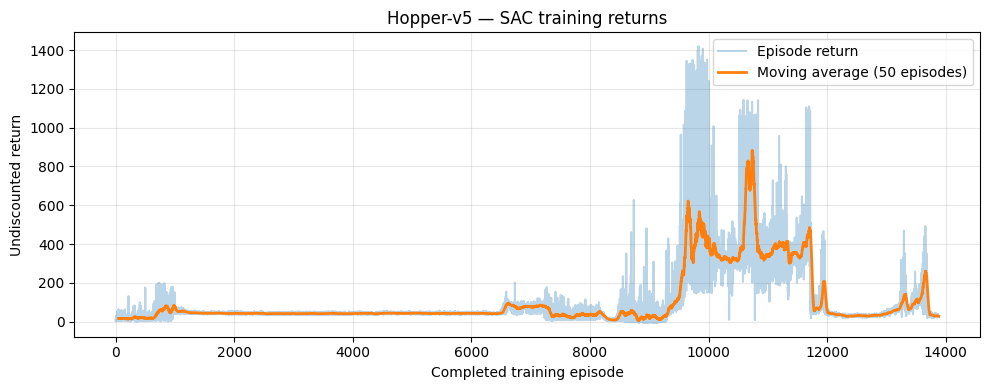

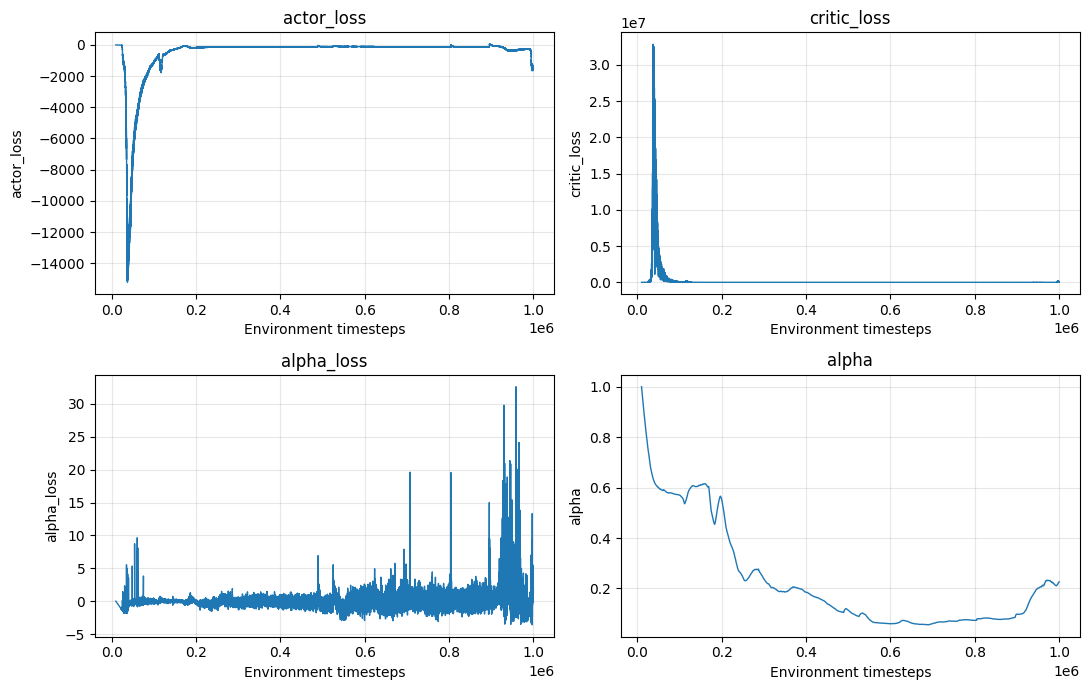

In [19]:
# 7. Visualize episode returns and optimization metrics
returns = np.asarray(agent.completed_returns, dtype=np.float64)
fig, ax = plt.subplots(figsize=(10, 4))
if len(returns):
    ax.plot(returns, alpha=0.3, label="Episode return")
    window = min(50, len(returns))
    smoothed = np.convolve(returns, np.ones(window)/window, mode="valid")
    ax.plot(np.arange(window-1, len(returns)), smoothed,
            linewidth=2, label=f"Moving average ({window} episodes)")
ax.set(xlabel="Completed training episode", ylabel="Undiscounted return",
       title="Hopper-v5 — SAC training returns")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(RUN_DIR / "episode_returns.png", dpi=160)
plt.show()

if history:
    fig, axs = plt.subplots(2, 2, figsize=(11, 7))
    keys = ["actor_loss", "critic_loss", "alpha_loss", "alpha"]
    steps = [row["timesteps"] for row in history]
    for ax, key in zip(axs.flat, keys):
        ax.plot(steps, [row[key] for row in history], linewidth=1)
        ax.set(xlabel="Environment timesteps", ylabel=key, title=key)
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(RUN_DIR / "optimization_metrics.png", dpi=160)
    plt.show()

In [ ]:
env_name = ENV_ID.split("-")[0].lower()                     # "halfcheetah", "ant", ...
checkpoint_path = Path(f"/network/rit/lab/dahlin_lab/Gobinda/Latent-Dynamics-Geometries/simplified/{env_name}_ldr_fn_results/{env_name}_ldr_fn_best.pt")

if checkpoint_path.exists():
    print("end-to-end test: loading checkpoint for inference")
    inference_env = makeVecEnv([make_env(ENV_ID, None, mode="nominal")])   # 1 env, nominal physics
    ckpt_cfg = torch.load(checkpoint_path, map_location="cpu", weights_only=True)["config"]
    inference_config = LDRConfig(**{**ckpt_cfg, "buffer_size": 1})
    inference_agent = LDRAgent(inference_env, env_ID=ENV_ID, config=inference_config)
    inference_agent.load(str(checkpoint_path))
    inference_env.close()
else:
    inference_agent = agent
print("Inference policy ready")

Loading checkpoint for inference: /network/rit/lab/dahlin_lab/Gobinda/Latent-Dynamics-Geometries/simplified/hopper_exp1_results/hopper_ldr_best.pt
Inference policy ready


In [ ]:
VIDEO_DIR = Path("./videos")
VIDEO_DIR.mkdir(exist_ok=True)

# Headless rendering environment
env = make_env(ENV_ID, None, mode="nominal", render_mode="rgb_array")()

obs, info = env.reset(seed=42)
history = HistoryQueue(1, inference_agent.config.n_past,
                       inference_agent.obs_dim, inference_agent.action_dim)
history.reset_done(np.ones(1, dtype=bool), obs[None])     # pad with initial obs

frames, total_reward = [], 0.0
fps = round(1.0 / env.unwrapped.dt)

for step in range(1000):
    action = inference_agent.predict(obs[None], history=history.get(),
                                     deterministic=True)[0]          # env-scale action

    next_obs, reward, terminated, truncated, info = env.step(action)

    # store (obs, normalized action), newest first
    history.append(obs[None], inference_agent._reverseEnvAction(action)[None])

    frames.append(env.render())
    total_reward += reward
    obs = next_obs
    if terminated or truncated:
        break

env.close()
video_path = VIDEO_DIR / "hopper_ldr.mp4"


imageio.mimsave(
    str(video_path),
    frames,
    fps=fps,
    macro_block_size=16
)

print(f"Episode reward: {total_reward:.2f}")
print(f"Video saved: {video_path.resolve()}")

# Display inside Jupyter
display(Video(
    filename=str(video_path),
    embed=True
))

Episode reward: 3547.48
Video saved: /network/rit/lab/dahlin_lab/Gobinda/Latent-Dynamics-Geometries/simplified/videos/hopper_ldr.mp4


In [ ]:
class EmbeddingVisualizer:

    # training ranges per parameter, used to normalise the 3-D parameter panel to [0, 1]
    PARAM_RANGES = {"mass": (0.5, 2.0), "damping": (0.5, 2.0), "torque_scale": (0.5, 1.5)}
    PARAM_AXES = ("mass", "damping", "torque_scale")

    def __init__(self, agent, env_id=None):

        self.agent = agent
        env_id = env_id or agent.env_ID
        self.env = make_env(env_id, None, mode="nominal")()
        self.friction_range = PHYSICS_SPECS[env_id.split("-")[0]]["friction_range"]

        # default physics, to scale from and restore
        self.model = self.env.unwrapped.model
        self.default_mass = self.model.body_mass.copy()
        self.default_friction = self.model.geom_friction.copy()
        self.default_damping = self.model.dof_damping.copy()
        self.torque_scale = 1.0

        self.n_past = agent.config.n_past
        self.obs_dim = agent.obs_dim
        self.action_dim = agent.action_dim
        self.device = agent.device

   
    def rollout(self, seed):
        """One deterministic episode; returns encoder means, shape (T, latent_dim)."""
        self.agent.encoder.eval()
        self.agent.actor.eval()

        history = HistoryQueue(1, self.n_past, self.obs_dim, self.action_dim)
        latents = []

        obs, _ = self.env.reset(seed=seed)
        history.reset_done(np.ones(1, dtype=bool), obs[None])   # pad with initial obs, as in training

        done = False
        while not done:
            with torch.no_grad():
                history_t = torch.as_tensor(history.get(), device=self.device)
                obs_t = torch.as_tensor(obs, dtype=torch.float32, device=self.device).reshape(1, -1)
                z = self.agent.encoder(history_t).loc                     # mean, no sampling
                action = self.agent.actor.predict(torch.cat([obs_t, z], dim=-1), deterministic=True)
            z, action = z.cpu().numpy()[0], action.cpu().numpy()[0]
            latents.append(z)

            env_action = self.agent._toEnvAction(action) * self.torque_scale
            next_obs, _, terminated, truncated, _ = self.env.step(env_action)

            # newest (obs, normalized action) pair goes to slot 0
            history.append(obs[None], action[None])

            obs = next_obs
            done = terminated or truncated

        return np.array(latents)

   
    def set_dynamics(self, param_name, scalar):
        """Scale ONE parameter group from default: 'mass', 'friction', 'damping', 'torque_scale'."""
        self.reset_dynamics()
        if param_name == "mass":
            self.model.body_mass[:] = self.default_mass * scalar
        elif param_name == "friction":
            friction = self.default_friction.copy()
            friction[:, 0] *= scalar
            self.model.geom_friction[:] = friction
        elif param_name == "damping":
            self.model.dof_damping[:] = self.default_damping * scalar
        elif param_name == "torque_scale":
            self.torque_scale = scalar
        else:
            raise ValueError(f"Unknown parameter: {param_name}")

    # def randomize_dynamics(self, rng):
    #     """Random draw from the training ranges (Xu's HopperDynamicsWrapper)."""
    #     self.model.body_mass[:] = self.default_mass * rng.uniform(0.5, 2.0, size=self.default_mass.shape)
    #     self.model.dof_damping[:] = self.default_damping * rng.uniform(0.5, 2.0, size=self.default_damping.shape)
    #     self.torque_scale = float(rng.uniform(0.5, 1.5))

    def randomize_dynamics(self, rng):
        """Random draw from Xu's training ranges (friction only for HalfCheetah/Ant)."""
        if self.friction_range is not None:
            fric = self.default_friction.copy()
            fric[:, 0] *= rng.uniform(*self.friction_range, size=fric.shape[0])
            self.model.geom_friction[:] = fric
        self.model.body_mass[:] = self.default_mass * rng.uniform(0.5, 2.0, size=self.default_mass.shape)
        self.model.dof_damping[:] = self.default_damping * rng.uniform(0.5, 2.0, size=self.default_damping.shape)
        self.torque_scale = float(rng.uniform(0.5, 1.5))

    def reset_dynamics(self):
        self.model.body_mass[:] = self.default_mass
        self.model.geom_friction[:] = self.default_friction
        self.model.dof_damping[:] = self.default_damping
        self.torque_scale = 1.0

    def current_param_scales(self):
        """
        Effective (mass, damping, torque_scale) multipliers of the current model.
        Mass and damping are randomised per body / per joint, so each is reduced to one number:
        total current value / total default value (mass-weighted and damping-weighted mean scale).
        Bodies/DOFs with zero default (world body, free root joints) contribute nothing.
        """
        def ratio(cur, default):
            tot = default.sum()
            return float(cur.sum() / tot) if tot > 0 else 1.0
        return np.array([ratio(self.model.body_mass, self.default_mass),
                         ratio(self.model.dof_damping, self.default_damping),
                         float(self.torque_scale)])


    def current_params(self):
            return np.array([float(self.model.body_mass.sum()/len(self.model.body_mass)),
                             float(self.model.dof_damping.sum()/len(self.model.dof_damping)),
                             float(self.torque_scale)])

    @classmethod
    def normalize_params(cls, params):
        """Map raw scales to [0, 1] per axis using the training range; OOD values fall outside [0, 1]."""
        lo = np.array([cls.PARAM_RANGES[k][0] for k in cls.PARAM_AXES])
        hi = np.array([cls.PARAM_RANGES[k][1] for k in cls.PARAM_AXES])
        return (np.asarray(params, dtype=float) - lo) / (hi - lo)

    
    def plot_separation(self, num_trajs=10, n_latents_per_traj=100, projection_method="pca", seed=0,
                        show_params=True):
        """One trajectory per random physics draw, coloured by trajectory (Xu: visualizeSeparationAcrossDynamics).
        show_params: add a 3-D panel with each trajectory's normalised (mass, damping, torque) in the same colour."""
        rng = np.random.default_rng(seed)
        all_latents, colors, params = [], [], []
        for i in range(num_trajs):
            self.randomize_dynamics(rng)
            params.append(self.current_param_scales()) #getting the scales of the parameters instead of the raw values
            # params.append(self.current_params()) # getting the raw values of the parameters instead of the scales
            latents = self._subsample(self.rollout(seed=seed + i), n_latents_per_traj)
            all_latents.append(latents)
            colors.extend([i] * len(latents))
        self.reset_dynamics()

        colors = np.array(colors)
        norm = plt.Normalize(vmin=colors.min(), vmax=colors.max())
        fig, ax, ax_p, pts = self._figure(np.concatenate(all_latents), projection_method, show_params)
        self._scatter(ax, pts, c=colors, cmap="jet", norm=norm, s=20, marker="o", alpha=0.8)

        if ax_p is not None:
            ids = np.arange(num_trajs)
            self._plot_params(ax_p, np.array(params), c=ids, cmap="jet", norm=norm,
                              labels=[str(i) for i in ids])

        cbar = fig.colorbar(cm.ScalarMappable(cmap="jet", norm=norm),
                            ax=[a for a in (ax, ax_p) if a is not None], pad=0.02, shrink=0.8)
        cbar.set_ticks(np.arange(num_trajs))
        cbar.set_label("Trajectory ID", fontsize=14)
        self.last_params = np.array(params)          # raw scales, one row per trajectory
        return fig, (ax, ax_p)

    def plot_physics_scan(self, param_name, scan_values, train_range, seed=1012,
                          n_latents_per_traj=100, projection_method="tsne", show_params=False):
        """
        Scale one parameter over scan_values, same seed (same start) each time
        (Xu: visualizeLatentSemanticStructure).
        train_range: [min, max) seen in training -> (0.5, 2.0) mass/damping, (0.5, 1.5) torque_scale
        show_params: add a 3-D panel with each scan's normalised (mass, damping, torque) in the same colour.
        """
        all_latents, values, ood, params = [], [], [], []
        for value in scan_values:
            self.set_dynamics(param_name, value)
            params.append(self.current_param_scales())
            latents = self._subsample(self.rollout(seed=seed), n_latents_per_traj)
            all_latents.append(latents)
            values.extend([value] * len(latents))
            ood.extend([value < train_range[0] or value >= train_range[1]] * len(latents))
        self.reset_dynamics()

        values, ood = np.array(values), np.array(ood, dtype=bool)
        norm = plt.Normalize(vmin=values.min(), vmax=values.max())
        fig, ax, ax_p, pts = self._figure(np.concatenate(all_latents), projection_method, show_params)
        for mask, marker, label in [(~ood, "o", "In-Distribution"), (ood, "^", "Out-Of-Distribution")]:
            if mask.any():
                self._scatter(ax, pts[mask], c=values[mask], cmap="RdBu_r", norm=norm,
                              s=20, marker=marker, label=label, alpha=0.8)

        if ax_p is not None:
            scan = np.array(scan_values, dtype=float)
            scan_ood = (scan < train_range[0]) | (scan >= train_range[1])
            self._plot_params(ax_p, np.array(params), c=scan, cmap="RdBu_r", norm=norm,
                              ood=scan_ood, labels=[f"{v:.2f}" for v in scan])

        cbar = fig.colorbar(cm.ScalarMappable(cmap="RdBu_r", norm=norm),
                            ax=[a for a in (ax, ax_p) if a is not None], pad=0.02, shrink=0.8)
        cbar.set_ticks(scan_values)
        cbar.set_label(f"{param_name} value", fontsize=14)
        # ax.legend(fontsize=14, loc="upper right", markerscale=2)
        self.last_params = np.array(params)
        return fig, (ax, ax_p)

    
    @staticmethod
    def _subsample(latents, n):
        idx = np.linspace(0, len(latents) - 1, min(len(latents), n), dtype=int)
        return latents[idx]

    @staticmethod
    def project(latents, method="pca", dim=2):
        """'pca' or 'tsne' to `dim` dims; returns input unchanged if it is already <= dim."""
        if latents.shape[1] <= dim:
            return latents.copy()
        if method == "pca":
            pca = PCA(n_components=dim)
            out = pca.fit_transform(latents)
            print("Cumulative explained variance:", np.cumsum(pca.explained_variance_ratio_))
            return out
        if method == "tsne":
            # Xu uses perplexity = N - 2; slow for large N, use 'pca' then
            return TSNE(n_components=dim, perplexity=len(latents) - 2, random_state=42).fit_transform(latents)
        raise ValueError("method must be 'pca' or 'tsne'")

    def _figure(self, latents, projection_method, show_params=False):
        """Latent panel ('3d' plots raw z or PCA to 3 dims; otherwise 2-D projection),
        plus an optional 3-D parameter panel to its right. Returns fig, ax, ax_params (or None), pts."""
        assert projection_method in ["pca", "tsne", "3d"]
        ncols = 2 if show_params else 1
        fig = plt.figure(figsize=(9 * ncols, 8.5))
        if projection_method == "3d":
            assert latents.shape[1] >= 3, "'3d' needs latent_dim >= 3"
            pts = self.project(latents, "pca", dim=3)
            ax = fig.add_subplot(1, ncols, 1, projection="3d")
            ax.view_init(elev=30, azim=45)
        else:
            pts = self.project(latents, projection_method, dim=2)
            ax = fig.add_subplot(1, ncols, 1)
            ax.set_xticks([])
            ax.set_yticks([])
        ax.set_title("Latent embedding", fontsize=14)
        ax_p = fig.add_subplot(1, ncols, 2, projection="3d") if show_params else None
        return fig, ax, ax_p, pts

    def _plot_params(self, ax, params, c, cmap, norm, ood=None, labels=None):
        """One point per trajectory at its normalised (mass, damping, torque_scale); [0,1]^3 = training box."""
        p = self.normalize_params(params)
        ood = np.zeros(len(p), dtype=bool) if ood is None else np.asarray(ood, dtype=bool)
        c = np.asarray(c)
        for mask, marker in [(~ood, "o"), (ood, "^")]:
            if mask.any():
                ax.scatter(p[mask, 0], p[mask, 1], p[mask, 2], c=c[mask], cmap=cmap, norm=norm,
                           s=90, marker=marker, edgecolors="k", linewidths=0.5, alpha=0.95, depthshade=False)
        if labels is not None:
            for (x, y, z), lab in zip(p, labels):
                ax.text(x, y, z, f" {lab}", fontsize=9)

        # wireframe of the training box [0, 1]^3
        for s in (0, 1):
            for t in (0, 1):
                ax.plot([0, 1], [s, s], [t, t], color="gray", lw=0.6, alpha=0.5)
                ax.plot([s, s], [0, 1], [t, t], color="gray", lw=0.6, alpha=0.5)
                ax.plot([s, s], [t, t], [0, 1], color="gray", lw=0.6, alpha=0.5)

        # axes cover the training box and any OOD points
        lo = np.minimum(p.min(axis=0), 0) - 0.05
        hi = np.maximum(p.max(axis=0), 1) + 0.05
        ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
        names = [f"{k}\n[{self.PARAM_RANGES[k][0]}, {self.PARAM_RANGES[k][1]})" for k in self.PARAM_AXES]
        ax.set_xlabel(names[0], fontsize=10); ax.set_ylabel(names[1], fontsize=10); ax.set_zlabel(names[2], fontsize=10)
        ax.view_init(elev=25, azim=45)
        ax.set_title("Normalised dynamics parameters scale", fontsize=14)

    @staticmethod
    def _scatter(ax, pts, **kwargs):
        if pts.shape[1] == 3:
            return ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], **kwargs)
        return ax.scatter(pts[:, 0], pts[:, 1], **kwargs)

    def close(self):
        self.env.close()



viz = EmbeddingVisualizer(inference_agent)

In [ ]:
### ORIGINAL CODE (commented out) 

# class EmbeddingVisualizer:
    
#     def __init__(self, agent, env_id="Hopper-v5"):
#         self.agent = agent
#         self.env = gym.make(env_id)

#         # default physics, to scale from and restore
#         self.model = self.env.unwrapped.model
#         self.default_mass = self.model.body_mass.copy()
#         self.default_friction = self.model.geom_friction.copy()
#         self.default_damping = self.model.dof_damping.copy()
#         self.torque_scale = 1.0

#         self.n_past = agent.config.n_past
#         self.obs_dim = agent.obs_dim
#         self.action_dim = agent.action_dim
#         self.device = agent.device

   
#     def rollout(self, seed):
#         """One deterministic episode; returns encoder means, shape (T, latent_dim)."""
#         self.agent.encoder.eval()
#         self.agent.actor.eval()

#         history = HistoryQueue(1, self.n_past, self.obs_dim, self.action_dim)
#         latents = []

#         obs, _ = self.env.reset(seed=seed)
#         history.reset_done(np.ones(1, dtype=bool), obs[None])   # pad with initial obs, as in training

#         done = False
#         while not done:
#             with torch.no_grad():
#                 history_t = torch.as_tensor(history.get(), device=self.device)
#                 obs_t = torch.as_tensor(obs, dtype=torch.float32, device=self.device).reshape(1, -1)
#                 z = self.agent.encoder(history_t).loc                     # mean, no sampling
#                 action = self.agent.actor.predict(torch.cat([obs_t, z], dim=-1), deterministic=True)
#             z, action = z.cpu().numpy()[0], action.cpu().numpy()[0]
#             latents.append(z)

#             env_action = self.agent._toEnvAction(action) * self.torque_scale
#             next_obs, _, terminated, truncated, _ = self.env.step(env_action)

#             # newest (obs, normalized action) pair goes to slot 0
#             history.append(obs[None], action[None])

#             obs = next_obs
#             done = terminated or truncated

#         return np.array(latents)

   
#     def set_dynamics(self, param_name, scalar):
#         """Scale ONE parameter group from default: 'mass', 'friction', 'damping', 'torque_scale'."""
#         self.reset_dynamics()
#         if param_name == "mass":
#             self.model.body_mass[:] = self.default_mass * scalar
#         elif param_name == "friction":
#             friction = self.default_friction.copy()
#             friction[:, 0] *= scalar
#             self.model.geom_friction[:] = friction
#         elif param_name == "damping":
#             self.model.dof_damping[:] = self.default_damping * scalar
#         elif param_name == "torque_scale":
#             self.torque_scale = scalar
#         else:
#             raise ValueError(f"Unknown parameter: {param_name}")

#     def randomize_dynamics(self, rng):
#         """Random draw from the training ranges (Xu's HopperDynamicsWrapper)."""
#         self.model.body_mass[:] = self.default_mass * rng.uniform(0.5, 2.0, size=self.default_mass.shape)
#         self.model.dof_damping[:] = self.default_damping * rng.uniform(0.5, 2.0, size=self.default_damping.shape)
#         self.torque_scale = float(rng.uniform(0.5, 1.5))

#     def reset_dynamics(self):
#         self.model.body_mass[:] = self.default_mass
#         self.model.geom_friction[:] = self.default_friction
#         self.model.dof_damping[:] = self.default_damping
#         self.torque_scale = 1.0

    
#     def plot_separation(self, num_trajs=10, n_latents_per_traj=100, projection_method="pca", seed=0):
#         """One trajectory per random physics draw, coloured by trajectory (Xu: visualizeSeparationAcrossDynamics)."""
#         rng = np.random.default_rng(seed)
#         all_latents, colors = [], []
#         for i in range(num_trajs):
#             self.randomize_dynamics(rng)
#             latents = self._subsample(self.rollout(seed=seed + i), n_latents_per_traj)
#             all_latents.append(latents)
#             colors.extend([i] * len(latents))
#         self.reset_dynamics()

#         colors = np.array(colors)
#         norm = plt.Normalize(vmin=colors.min(), vmax=colors.max())
#         fig, ax, pts = self._figure(np.concatenate(all_latents), projection_method)
#         self._scatter(ax, pts, c=colors, cmap="jet", norm=norm, s=20, marker="o", alpha=0.8)

#         cbar = fig.colorbar(cm.ScalarMappable(cmap="jet", norm=norm), ax=ax, pad=0.01)
#         cbar.set_ticks(np.arange(num_trajs))
#         cbar.set_label("Trajectory ID", fontsize=14)
#         return fig, ax

#     def plot_physics_scan(self, param_name, scan_values, train_range, seed=1012,
#                           n_latents_per_traj=100, projection_method="tsne"):
#         """
#         Scale one parameter over scan_values, same seed (same start) each time
#         (Xu: visualizeLatentSemanticStructure).
#         train_range: [min, max) seen in training -> (0.5, 2.0) mass/damping, (0.5, 1.5) torque_scale
#         """
#         all_latents, values, ood = [], [], []
#         for value in scan_values:
#             self.set_dynamics(param_name, value)
#             latents = self._subsample(self.rollout(seed=seed), n_latents_per_traj)
#             all_latents.append(latents)
#             values.extend([value] * len(latents))
#             ood.extend([value < train_range[0] or value >= train_range[1]] * len(latents))
#         self.reset_dynamics()

#         values, ood = np.array(values), np.array(ood, dtype=bool)
#         norm = plt.Normalize(vmin=values.min(), vmax=values.max())
#         fig, ax, pts = self._figure(np.concatenate(all_latents), projection_method)
#         for mask, marker, label in [(~ood, "o", "In-Distribution"), (ood, "^", "Out-Of-Distribution")]:
#             if mask.any():
#                 self._scatter(ax, pts[mask], c=values[mask], cmap="RdBu_r", norm=norm,
#                               s=20, marker=marker, label=label, alpha=0.8)

#         cbar = fig.colorbar(cm.ScalarMappable(cmap="RdBu_r", norm=norm), ax=ax, pad=0.01)
#         cbar.set_ticks(scan_values)
#         cbar.set_label(f"{param_name} value", fontsize=14)
#         ax.legend(fontsize=14, loc="upper right", markerscale=2)
#         return fig, ax

    
#     @staticmethod
#     def _subsample(latents, n):
#         idx = np.linspace(0, len(latents) - 1, min(len(latents), n), dtype=int)
#         return latents[idx]

#     @staticmethod
#     def project(latents, method="pca", dim=2):
#         """'pca' or 'tsne' to `dim` dims; returns input unchanged if it is already <= dim."""
#         if latents.shape[1] <= dim:
#             return latents.copy()
#         if method == "pca":
#             pca = PCA(n_components=dim)
#             out = pca.fit_transform(latents)
#             print("Cumulative explained variance:", np.cumsum(pca.explained_variance_ratio_))
#             return out
#         if method == "tsne":
#             # Xu uses perplexity = N - 2; slow for large N, use 'pca' then
#             return TSNE(n_components=dim, perplexity=len(latents) - 2, random_state=42).fit_transform(latents)
#         raise ValueError("method must be 'pca' or 'tsne'")

#     def _figure(self, latents, projection_method):
#         """'3d' plots raw z (latent_dim == 3) or PCA to 3 dims; otherwise 2-D projection."""
#         assert projection_method in ["pca", "tsne", "3d"]
#         if projection_method == "3d":
#             assert latents.shape[1] >= 3, "'3d' needs latent_dim >= 3"
#             pts = self.project(latents, "pca", dim=3)
#             fig = plt.figure(figsize=(9, 9))
#             ax = fig.add_subplot(111, projection="3d")
#             ax.view_init(elev=30, azim=45)
#         else:
#             pts = self.project(latents, projection_method, dim=2)
#             fig, ax = plt.subplots(figsize=(8, 8))
#             ax.set_xticks([])
#             ax.set_yticks([])
#         return fig, ax, pts

#     @staticmethod
#     def _scatter(ax, pts, **kwargs):
#         if pts.shape[1] == 3:
#             return ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], **kwargs)
#         return ax.scatter(pts[:, 0], pts[:, 1], **kwargs)

#     def close(self):
#         self.env.close()



# viz = EmbeddingVisualizer(inference_agent)

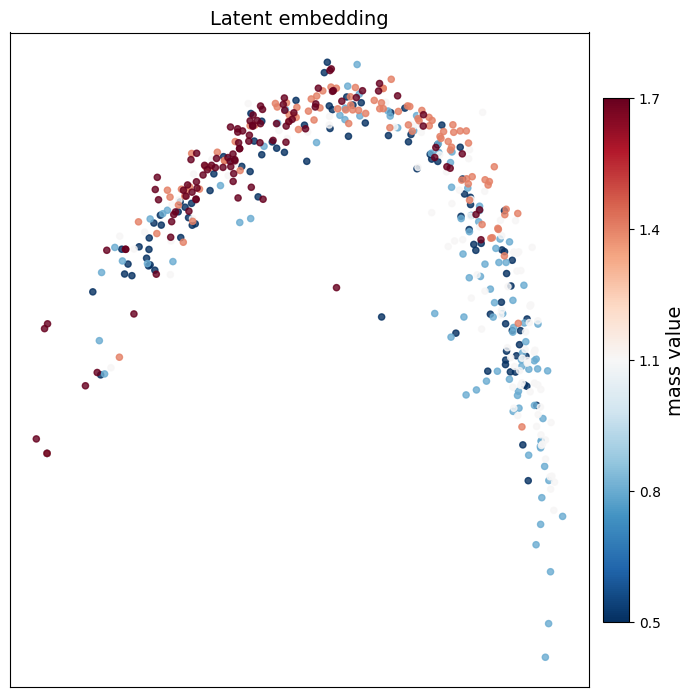

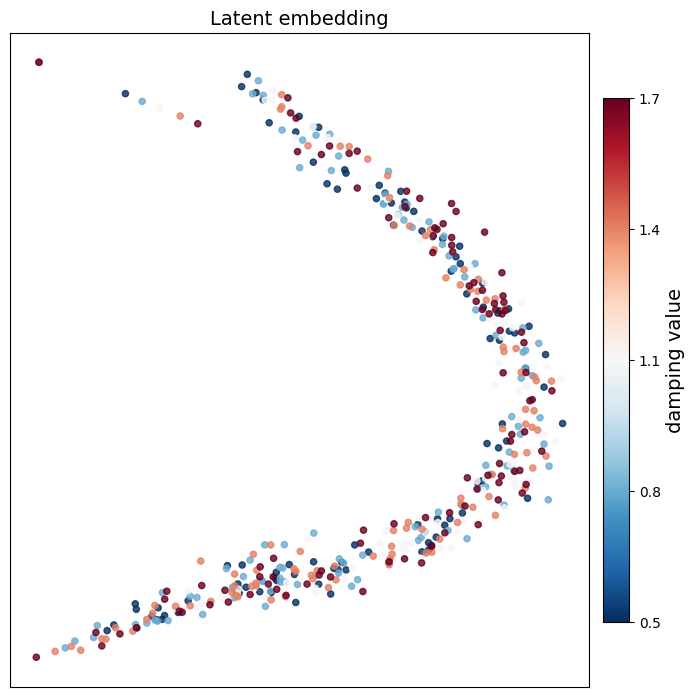

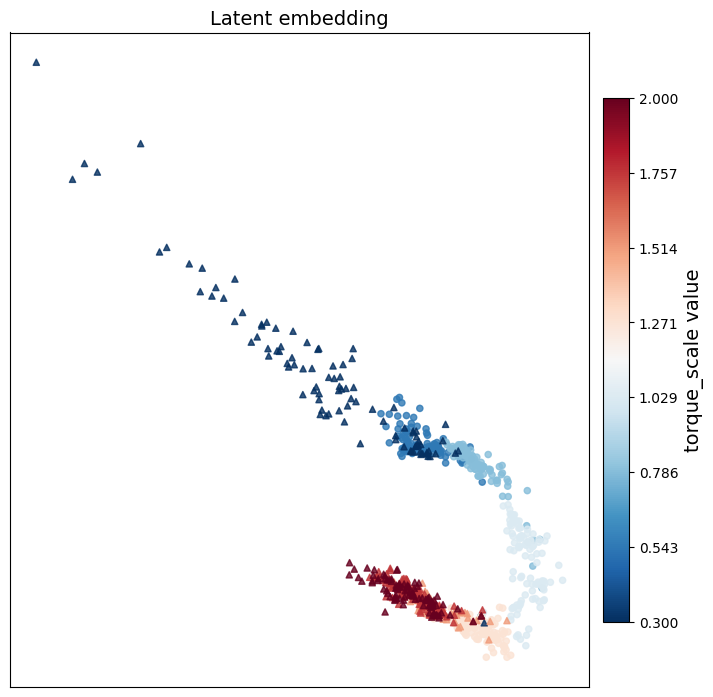

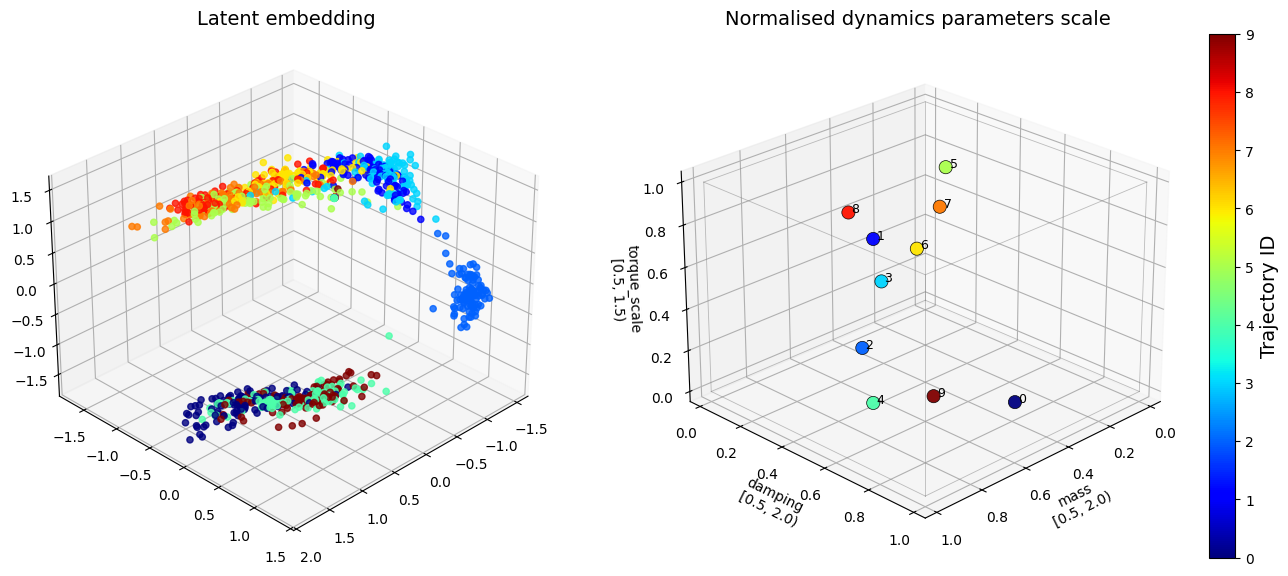

In [ ]:
viz = EmbeddingVisualizer(inference_agent)

fig, ax = viz.plot_physics_scan(
    param_name="mass",
    scan_values=np.linspace(0.5, 2.0, 5, endpoint=False).tolist(),
    train_range=(0.5, 2.0),
    projection_method="tsne",
)
# fig.savefig("latent_mass_scan.png", dpi=150, bbox_inches="tight")

fig, ax = viz.plot_physics_scan(
    param_name="damping",
    scan_values=np.linspace(0.5, 2.0, 5, endpoint=False).tolist(),
    train_range=(0.5, 2.0),
    projection_method="tsne",
)

fig, ax = viz.plot_physics_scan(
    param_name="torque_scale",
    scan_values=np.linspace(0.3, 2.0, 8).tolist(),
    train_range=(0.5, 1.5),
    projection_method="tsne",
)
# fig.savefig("latent_torque_scan.png", dpi=150, bbox_inches="tight")

fig, ax = viz.plot_separation(num_trajs=10, projection_method="3d")
# fig.savefig("latent_separation.png", dpi=150, bbox_inches="tight")

viz.close()